# MODÈLE PRINCIPAL — tarification automobile

**Recette retenue : `frequency_curves_1365_657`.**

Ce notebook est le point de lecture principal. Il explique les données, les variables,
les modèles réellement utilisés, leur apprentissage, la validation, leurs faiblesses
et la soumission. Les versions précédentes sont conservées dans `archive/`.

Le **score public communiqué est 1365,657**, associé à un CSV précis dans le reçu
historique. Il n'a pas été vérifié à nouveau sur Kaggle. La **RMSE locale historique
est 541,915571 €**, sur d'autres observations : ces deux nombres ne sont pas
interchangeables. Le modèle est destiné à l'exercice, pas à un tarif commercial
annuel dont l'exposition et les frais seraient documentés.

Environnement : Python 3.12 et `requirements-main.txt`. Les cellules utilisent le
code Python partagé du projet ; elles ne chargent jamais le code d'un autre notebook.
Les sections « code exact » affichent les sources des objets effectivement utilisés.

In [1]:
from pathlib import Path
import sys,json,inspect,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Code
from threadpoolctl import threadpool_limits
roots=[Path.cwd(),*Path.cwd().parents]
ROOT=next(p for p in roots if (p/'Data/train.csv').exists() and (p/'src/pricing').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from pricing import main_model as main
from pricing import reference as reference_code
f=main.libraries()
threadpool_limits(limits=4)
OUT=ROOT/'reports/main';FIG=OUT/'figures';FIG.mkdir(parents=True,exist_ok=True)
def figure(fig,name):
    fig.tight_layout();fig.savefig(FIG/name,dpi=150,bbox_inches='tight');display(fig);plt.close(fig)
def scores(y,p):return f.r.score(np.asarray(y),np.asarray(p))

## 1. Cadrage : que prédit-on ?

Pour un contrat décrit par X :

\[\widehat{\mathrm{prime}}(X)=\widehat p(X)\times\widehat s(X).\]

`p` est la probabilité d'au moins un sinistre ; `s` est le coût moyen **conditionnel
à un sinistre**. Le coût réel vaut zéro sans sinistre. La fréquence apprend sur
tous les contrats ; la gravité seulement sur les sinistres positifs.

Nous prédisons une gravité conditionnelle pour **chaque prospect**, car son accident
futur n'est pas connu. Aucun seuil de classification ne décide qui paiera une
prime nulle. La MSE de prime sert à sélectionner ; sa racine, la RMSE, exprime
l'erreur en euros. `pred` dans le CSV est une prime, jamais une RMSE.

In [2]:
train,test,dev,historique=f.r.load_data()
claims=train.loc[train.nombre_sinistres.eq(1)]
etat=pd.DataFrame([
    {'jeu':'Train','contrats':len(train),'clients':train.id_client.nunique(),'sinistres':len(claims),'cibles_connues':True},
    {'jeu':'Test prospects','contrats':len(test),'clients':np.nan,'sinistres':np.nan,'cibles_connues':False}])
display(etat)
print(f'Taux de sinistre : {len(claims)/len(train):.3%}.')
print('Le test ne contient pas les identifiants clients : on ne peut pas mesurer leur recouvrement avec le train.')
print('Index du test :',test['index'].min(),'à',test['index'].max())
display(claims.montant_sinistre.describe(percentiles=[.5,.9,.95,.99]).to_frame('coût conditionnel (€)'))
assert main.sha256(ROOT/'Data/train.csv')=='8b5ca8a59c214269056ed1720de33619c10968549c383ec350898a659b97bfc5'
assert main.sha256(ROOT/'Data/test.csv')=='68cdf87201974688d754d846c2d8ff33c5aa2f9c011e84fba92018186cd8f569'

Taux de sinistre : 5.834%.
Le test ne contient pas les identifiants clients : on ne peut pas mesurer leur recouvrement avec le train.
Index du test : 50000 à 99999


,jeu,contrats,clients,sinistres,cibles_connues
0,Train,50000,45785.0,2917.0,True
1,Test prospects,50000,NaN,NaN,False


,coût conditionnel (€)
count,2917.000000
mean,1771.843401
std,1463.954673
min,600.600000
50%,1236.000000
90%,3336.740000
95%,4355.258000
99%,6963.118800
max,21826.960000


## 2. Comprendre la cible et les données

La majorité des contrats n'a aucun coût. Parmi les sinistrés, les montants sont
très asymétriques. Leur moyenne dépasse la médiane et quelques grands sinistres
pèsent fortement dans une perte quadratique. Nous ne les supprimons pas et ne
remplaçons pas la moyenne conditionnelle par une médiane issue d'un logarithme.

Le minimum positif observé n'est pas une preuve de franchise contractuelle connue.
Les durées ne sont pas annualisées. Les variables de vente et de permis comportent
des valeurs dont le sens ou la cohérence doivent être documentés.

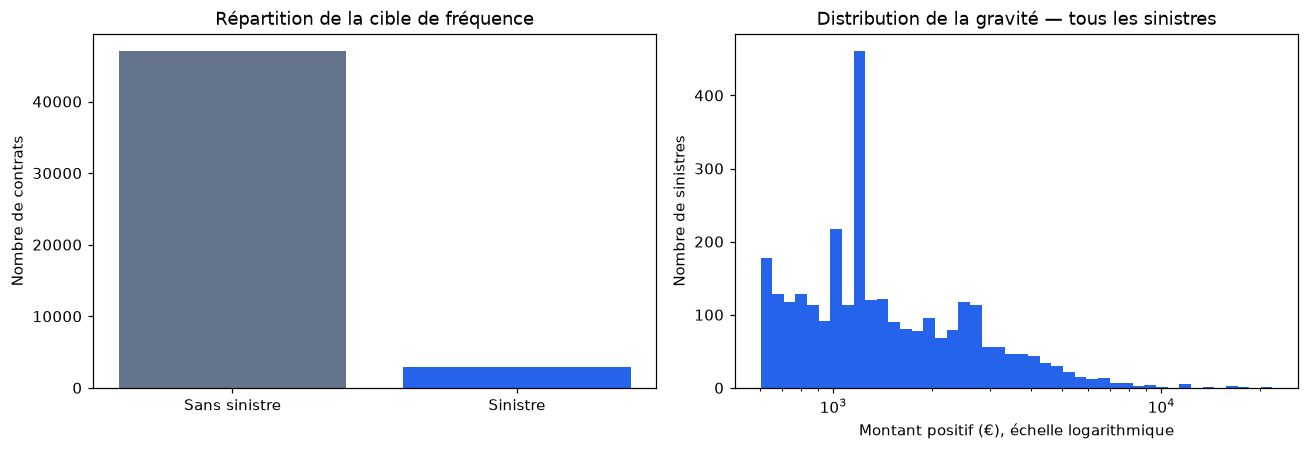

,variable,type,manquants_train,manquants_test,modalites_train,nouvelles_modalites_test
0,bonus,float64,0,0,73,NaN
1,type_contrat,str,0,0,4,0.0
2,duree_contrat,int64,0,0,41,NaN
3,anciennete_info,int64,0,0,25,NaN
4,freq_paiement,str,0,0,4,0.0
5,paiement,str,0,0,2,0.0
6,utilisation,str,0,0,4,0.0
7,code_postal,str,0,0,12790,7482.0
8,conducteur2,str,0,0,2,0.0
9,age_conducteur1,int64,0,0,83,NaN


,poids_nul,cylindree_nulle,permis1_superieur_age1,age_second_conducteur_nul
0,1883,3,12,33406


In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
counts=train.nombre_sinistres.value_counts().reindex([0,1])
axes[0].bar(['Sans sinistre','Sinistre'],counts,color=['#64748b','#2563eb'])
axes[0].set(title='Répartition de la cible de fréquence',ylabel='Nombre de contrats')
positive=claims.montant_sinistre.to_numpy()
axes[1].hist(positive,bins=np.geomspace(positive.min(),positive.max(),45),color='#2563eb')
axes[1].set(xscale='log',xlabel='Montant positif (€), échelle logarithmique',ylabel='Nombre de sinistres',title='Distribution de la gravité — tous les sinistres')
figure(fig,'01_cibles.png')
audit=[]
for col in reference_code.RAW_FEATURES:
    a,b=train[col],test[col]
    audit.append({'variable':col,'type':str(a.dtype),'manquants_train':int(a.isna().sum()),
        'manquants_test':int(b.isna().sum()),'modalites_train':int(a.nunique()),
        'nouvelles_modalites_test':int((b.notna() & ~b.isin(a.dropna())).sum()) if not pd.api.types.is_numeric_dtype(a) else np.nan})
audit=pd.DataFrame(audit);audit.to_csv(OUT/'audit_variables.csv',index=False);display(audit)
anomalies=pd.DataFrame({
    'poids_nul':[int(train.poids_vehicule.eq(0).sum())],
    'cylindree_nulle':[int(train.cylindre_vehicule.eq(0).sum())],
    'permis1_superieur_age1':[int(train.anciennete_permis1.gt(train.age_conducteur1).sum())],
    'age_second_conducteur_nul':[int(train.age_conducteur2.eq(0).sum())]})
display(anomalies)

### Corrélations : diagnostic, pas règle automatique de sélection

Les corrélations de Spearman comparent les rangs des variables quantitatives. Elles
peuvent révéler la redondance entre caractéristiques de véhicule ou entre âge et
permis. Elles ne décrivent pas correctement toutes les catégories, interactions,
non-linéarités ou effets conditionnels. La cible de gravité est étudiée seulement
sur les sinistrés. Ces graphiques ne déclenchent aucun nouveau réglage du modèle.

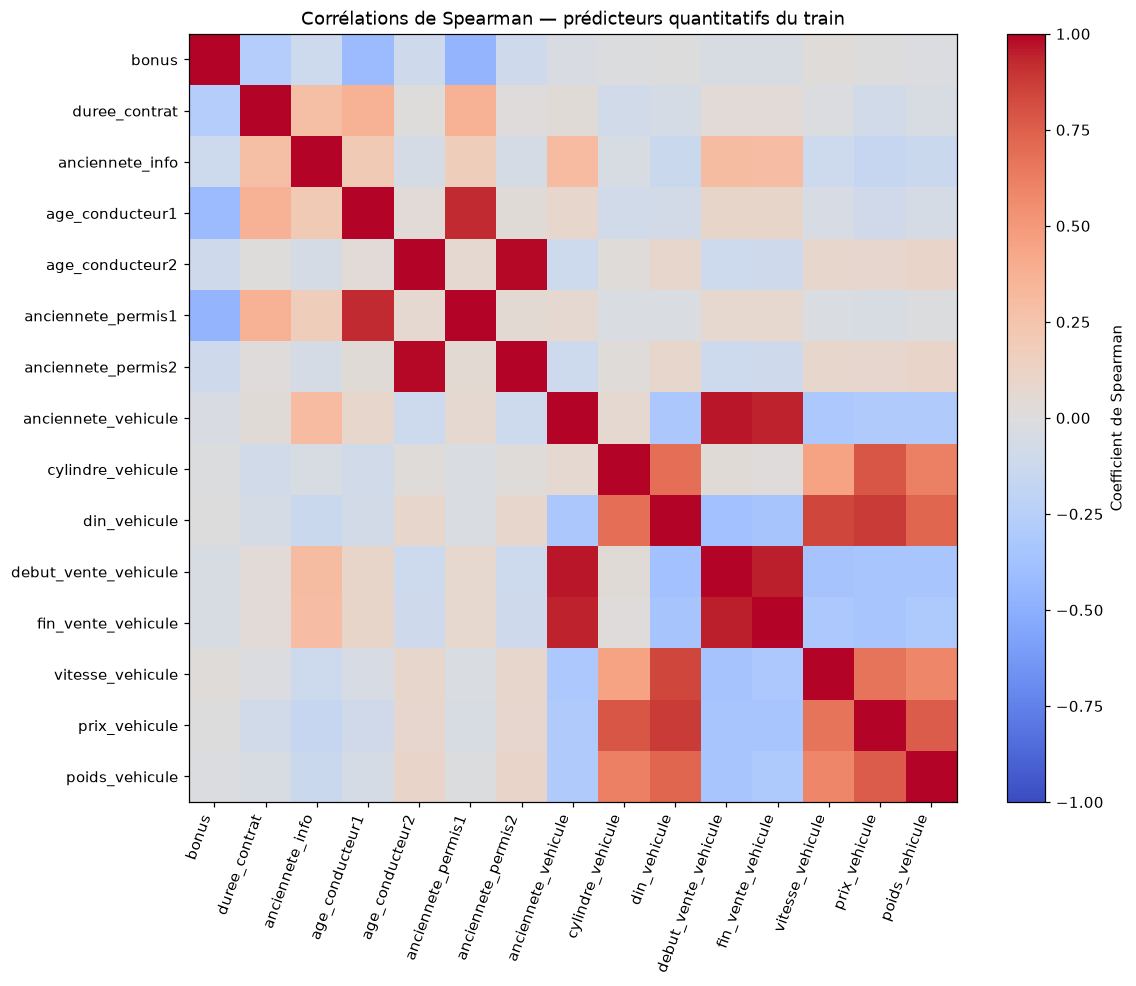

,"association avec la gravité, sinistrés seulement"
anciennete_vehicule,-0.085035
fin_vente_vehicule,-0.073929
debut_vente_vehicule,-0.072389
cylindre_vehicule,-0.042509
poids_vehicule,-0.030328
prix_vehicule,-0.029343
duree_contrat,-0.024378
anciennete_permis1,-0.022167
din_vehicule,-0.018707
age_conducteur1,-0.015864


In [4]:
numeriques=[c for c in reference_code.RAW_FEATURES if pd.api.types.is_numeric_dtype(train[c])]
corr=train[numeriques].corr(method='spearman')
corr.to_csv(OUT/'correlations_spearman.csv')
fig,ax=plt.subplots(figsize=(11,9))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr)),corr.columns,rotation=70,ha='right');ax.set_yticks(range(len(corr)),corr.index)
ax.set_title('Corrélations de Spearman — prédicteurs quantitatifs du train')
fig.colorbar(im,ax=ax,label='Coefficient de Spearman');figure(fig,'02_correlations.png')
association=claims[numeriques+['montant_sinistre']].corr(method='spearman')['montant_sinistre'].drop('montant_sinistre').sort_values()
display(association.to_frame('association avec la gravité, sinistrés seulement'))

## 3. Architecture exacte du modèle principal

**Fréquence :** `p = sigmoid(logit(p0) + correction_age_couverture_usage)`.

**Gravité :** `s = 0,375 × Gamma + 0,375 × Gamma corrigé par XGBoost + 0,25 × Gamma corrigé par Ridge`.

**Prime :** `p × s`.

Les poids de gravité résultent de deux mélanges successifs : 50/50 Gamma–XGBoost,
puis 75 % de ce mélange et 25 % de Ridge. Le modèle n'est donc ni une régression
linéaire ordinaire, ni un Gamma pur à trois variables. Le Gamma reste son ancre.

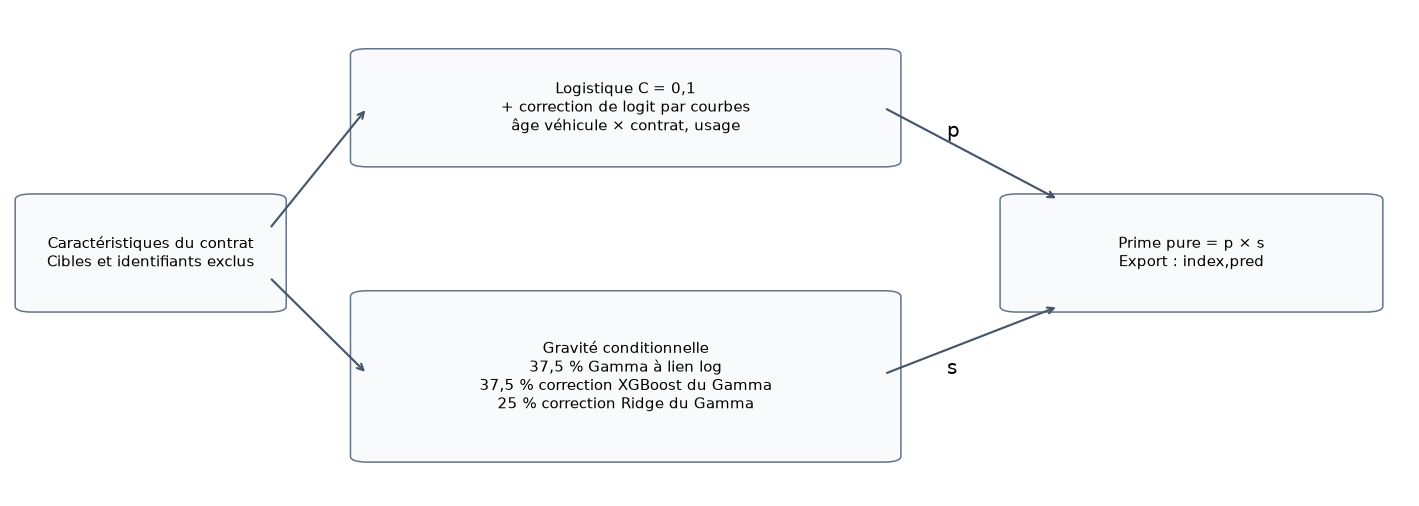

,name,target,frequency.base,frequency.correction.panel,frequency.correction.alpha,frequency.correction.weight,frequency.correction.knots,frequency.correction.degree,frequency.correction.interaction_scale,severity.gamma.alpha,severity.gamma.weight,severity.xgboost_ratio.depth,severity.xgboost_ratio.trees,severity.xgboost_ratio.learning_rate,severity.xgboost_ratio.min_child_weight,severity.xgboost_ratio.reg_lambda,severity.xgboost_ratio.reg_alpha,severity.xgboost_ratio.seed,severity.xgboost_ratio.weight,severity.ridge_ratio.panel,severity.ridge_ratio.alpha,severity.ridge_ratio.knots,severity.ridge_ratio.degree,severity.ridge_ratio.rare_claims,severity.ridge_ratio.weight
0,frequency_curves_1365_657,cout_observe_periode_non_annualise,logistique_C0.1_encodage_cible_hors_client,age_coverage,100.0,1.0,4,2,0.5,0.1,0.375,2,240,0.025,100.0,100.0,1.0,20261012,0.375,all,10.0,4,2,15,0.25


In [5]:
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(13,4.7));ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
def box(x,y,w,h,text):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.012',facecolor='#f8fafc',edgecolor='#64748b'))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=10)
def arrow(a,b):ax.annotate('',xy=b,xytext=a,arrowprops={'arrowstyle':'->','color':'#475569','lw':1.4})
box(.015,.39,.17,.22,'Caractéristiques du contrat\nCibles et identifiants exclus')
box(.255,.69,.37,.22,'Logistique C = 0,1\n+ correction de logit par courbes\nâge véhicule × contrat, usage')
box(.255,.08,.37,.33,'Gravité conditionnelle\n37,5 % Gamma à lien log\n37,5 % correction XGBoost du Gamma\n25 % correction Ridge du Gamma')
box(.72,.39,.25,.22,'Prime pure = p × s\nExport : index,pred')
arrow((.185,.55),(.255,.8));arrow((.185,.45),(.255,.25))
arrow((.625,.8),(.75,.61));arrow((.625,.25),(.75,.39))
ax.text(.67,.74,'p',fontsize=13);ax.text(.67,.25,'s',fontsize=13)
figure(fig,'03_architecture.png')
display(pd.json_normalize(main.RECIPE))

### Variables conservées : distinguer chaque composante

« Trois variables » ne décrit que le Gamma et la correction XGBoost de base.
La logistique et la Ridge utilisent davantage d'informations. Le département
intervient dans la fréquence et la Ridge, sans entrer dans le Gamma. Être utilisé
ne signifie pas qu'un champ apporte à lui seul un gain causal ou statistiquement net.
La fin de vente n'est utilisée par aucune des composantes retenues.

In [6]:
base_frequency=set(reference_code.RAW_FEATURES)-set(reference_code.REDONDANTES)
basic={'anciennete_vehicule','type_contrat','utilisation'}
ridge_raw=set(reference_code.RAW_FEATURES)-{'fin_vente_vehicule'}
rows=[]
for col in reference_code.RAW_FEATURES:
    rows.append({'champ':col,'logistique_base':col in base_frequency,'correction_frequence':col in basic,
        'Gamma':col in basic,'correction_XGBoost':col in basic,'correction_Ridge':col in ridge_raw,
        'note':'transformé en département' if col=='code_postal' else 'inutilisé' if col=='fin_vente_vehicule' else ''})
usage=pd.DataFrame(rows);usage.to_csv(OUT/'variables_par_composante.csv',index=False);display(usage)
print('Exclus : index, id_client, id_vehicule, id_contrat, sexes et cibles.')
print('Ridge : les variables dérivées comprennent absence du second conducteur, anomalies de permis, zéros techniques et écart de vente/âge.')

Exclus : index, id_client, id_vehicule, id_contrat, sexes et cibles.
Ridge : les variables dérivées comprennent absence du second conducteur, anomalies de permis, zéros techniques et écart de vente/âge.


,champ,logistique_base,correction_frequence,Gamma,correction_XGBoost,correction_Ridge,note
0,bonus,True,False,False,False,True,
1,type_contrat,True,True,True,True,True,
2,duree_contrat,True,False,False,False,True,
3,anciennete_info,True,False,False,False,True,
4,freq_paiement,True,False,False,False,True,
5,paiement,True,False,False,False,True,
6,utilisation,True,True,True,True,True,
7,code_postal,True,False,False,False,True,transformé en département
8,conducteur2,True,False,False,False,True,
9,age_conducteur1,True,False,False,False,True,


## 4. Comment la fréquence apprend-elle ?

La base est une logistique régularisée L2 (`C = 0,1`). Imputation hiérarchique,
logarithmes `log1p`, standardisation, catégories rares et encodages de cible sont
appris dans l'apprentissage autorisé. Marque, modèle et département sont encodés
par taux lissé (`lissage = 100`) ; les valeurs d'apprentissage excluent le client
concerné, et leur prior exclut aussi son pli.

La correction finale utilise des splines quadratiques de l'âge du véhicule à
quatre nœuds uniformes, des catégories contrat/usage et leurs interactions avec
l'âge du véhicule. Les interactions sont multipliées par 0,5. Elle minimise la
somme des log-loss binomiales avec pénalisation L2 **alpha = 100**, intercept
compris. Son poids final est 1 : toute la correction est ajoutée au logit.

Pour apprendre cette correction, ses probabilités de base proviennent de trois
sous-plis séparés par client. Pour prédire, la base est réapprise sur tout
l'apprentissage autorisé. Aucun poids de classe ne force un équilibre artificiel.

In [7]:
# Code exact des principales étapes d'encodage et de la correction retenue.
for obj in [reference_code.encoder_hors_clients,reference_code.apprendre_frequence,
            reference_code.ReferenceFrequence,f.loss_gradient,f.Correction]:
    display(Markdown('**'+obj.__name__+'**'));display(Code(inspect.getsource(obj),language='python'))

**encoder_hors_clients**

def encoder_hors_clients(x, y, groupes):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    encodage = pd.DataFrame(np.nan, index=x.index, columns=CAT_FORTE)
    audit = []
    for k, (a, b) in enumerate(cv.split(x, y, groups=groupes), 1):
        assert set(groupes.iloc[a]).isdisjoint(groupes.iloc[b])
        prior = float(y.iloc[a].mean())
        for col in CAT_FORTE:
            mapping = taux_lisse(x.iloc[a][col], y.iloc[a], prior)
            encodage.loc[x.index[b], col] = x.iloc[b][col].map(mapping).fillna(prior).to_numpy()
        audit.append({'pli': k, 'contrats_apprentissage': len(a),
            'contrats_encodés': len(b), 'clients_communs': 0, 'prior_autres_plis': prior})
    assert np.isfinite(encodage.to_numpy()).all()
    return encodage, pd.DataFrame(audit)

**apprendre_frequence**

def apprendre_frequence(frame, y, groupes):
    assert frame.index.is_unique and frame.index.equals(y.index)
    assert frame.index.equals(groupes.index)
    x = nettoyer_frequence(frame)
    p = {'taux_moyen': float(y.mean())}
    for col in A_IMPUTER:
        p[f'med_modele_{col}'] = x.groupby('modele_vehicule')[col].median()
        p[f'med_marque_{col}'] = x.groupby('marque_vehicule')[col].median()
        p[f'med_globale_{col}'] = float(x[col].median())
    for col in CAT_FAIBLE:
        counts = x[col].value_counts()
        p[f'frequentes_{col}'] = counts[counts >= SEUIL_RARE].index
        p[f'reference_{col}'] = counts.index[0]
    for col in CAT_FORTE:
        p[f'taux_{col}'] = taux_lisse(x[col], y, p['taux_moyen'])
    oof, audit = encoder_hors_clients(x, y, groupes)
    z = transformer_frequence(frame, p, encodage=oof)
    p['colonnes'] = z.columns
    p['colonnes_num'] = [col for col in z if z[col].nunique() > 2]
    p['moyennes'] = z[p['colonnes_num']].mean()
    p['ecarts_types'] = z[p['colonnes_num']].std().replace(0, 1)
    return p, standardiser_frequence(z, p), audit

**ReferenceFrequence**

class ReferenceFrequence:
    def fit(self,X,y,groups):
        y=pd.Series(np.asarray(y),index=X.index)
        groups=pd.Series(np.asarray(groups),index=X.index)
        self.params_,z,self.audit_=apprendre_frequence(X,y,groups)
        self.model_=LogisticRegression(C=.1,max_iter=3000)
        self.model_.fit(z,y)
        return self
    def predict_proba(self,X):return self.model_.predict_proba(preparer_frequence(X,self.params_))

**loss_gradient**

def loss_gradient(beta,z,y,offset,alpha):
    eta=offset+z@beta
    loss=float(np.sum(np.logaddexp(0,eta)-y*eta)+.5*alpha*np.dot(beta,beta))
    grad=z.T@(expit(eta)-y)+alpha*beta
    return loss,grad

**Correction**

class Correction:
    def __init__(self,c):self.config=c
    def frame(self,X):
        x=previous.preparer_metier(X)
        nums=['anciennete_vehicule'] if self.config['panel']!='compact' else ['anciennete_vehicule','age_conducteur1','log_bonus','log_prix','log_din']
        cats=[] if self.config['panel']=='vehicle' else ['type_contrat','utilisation']
        for c in cats:x[c]=x[c].astype('string').fillna('__MISSING__').astype(str)
        return x[nums+cats],nums,cats
    def matrix(self,X,fit=False):
        x,n,c=self.frame(X)
        if fit:
            parts=[('curves',Pipeline([('missing',SimpleImputer(strategy='median')),
                ('splines',SplineTransformer(n_knots=4,degree=2,include_bias=False,extrapolation='constant')),
                ('scale',StandardScaler())]),n)]
            if c:parts.append(('categories',OneHotEncoder(handle_unknown='ignore',min_frequency=50,sparse_output=False),c))
            self.prep_=ColumnTransformer(parts);z=self.prep_.fit_transform(x)
        else:z=self.prep_.transform(x)
        if self.config['panel']=='age_coverage':
            if fit:
                names=self.prep_.get_feature_names_out()
                self.numeric_=[i for i,a in enumerate(names) if a.startswith('curves__')]
                self.coverage_=[i for i,a in enumerate(names) if a.startswith('categories__type_contrat_')]
            cross=z[:,self.numeric_][:,:,None]*z[:,self.coverage_][:,None,:]
            z=np.column_stack([z,.5*cross.reshape(len(z),-1)])
        return np.column_stack([np.ones(len(z)),z])
    def fit(self,learn,p):
        z=self.matrix(learn,True);y=learn.nombre_sinistres.to_numpy();offset=logit(p)
        opt=minimize(loss_gradient,np.zeros(z.shape[1]),args=(z,y,offset,self.config['alpha']),jac=True,
            method='L-BFGS-B',options=dict(maxiter=500,ftol=1e-12,gtol=1e-6))
        assert opt.success,opt.message;self.coef_=opt.x;self.convergence_=dict(iterations=int(opt.nit),loss=float(opt.fun))
        return self
    def delta(self,X):return self.matrix(X)@self.coef_

## 5. Comment la gravité apprend-elle ?

**Gamma :** lien log, `alpha = 0,1`, type de contrat, ancienneté du véhicule,
utilisation. Il prédit une moyenne positive et optimise sa déviance régularisée.

**XGBoost :** 240 arbres de profondeur 2, taux d'apprentissage 0,025,
`min_child_weight = 100`, L2 = 100, L1 = 1, seed 20261012. Il apprend le ratio
coût/Gamma hors client, à partir des mêmes trois variables. Son montant corrigé
est Gamma multiplié par ce ratio prédit, avec protection de positivité.

**Ridge :** alpha = 10, panneau complet véhicule/conducteur/contrat/département,
splines quadratiques à quatre nœuds, regroupement des catégories à moins de
15 sinistres. Il apprend coût/Gamma hors client − 1 et corrige le Gamma par ce ratio.

Les probabilités et Gamma auxiliaires sont appris hors client dans trois plis.
La probabilité auxiliaire de gravité vient d'une logistique compacte ; elle n'est
pas la fréquence finale corrigée. Le poids des corrections est proportionnel à
`p_aux × Gamma_aux²`, normalisé à moyenne 1. L'identité
`p×s²×(y/s−r)² = p×(y−s×r)²` explique l'échelle de cette pondération.

Tous les grands sinistres sont conservés. Les planchers numériques positifs ne
sont ni des franchises connues ni une suppression des coûts extrêmes.

In [8]:
for obj in [reference_code.GammaMetier,f.previous.moments,f.old.Correction,
            f.vm.features,f.vm.Correction]:
    display(Markdown('**'+obj.__module__+'.'+obj.__name__+'**'));display(Code(inspect.getsource(obj),language='python'))

**pricing.reference.GammaMetier**

class GammaMetier:
    def __init__(self,config):self.config=config
    def _spec(self):
        c=self.config
        nums=['anciennete_vehicule'];cats=['type_contrat','utilisation']
        if c.get('compact'):nums+=['log_prix','age_conducteur1','log_din'];cats+=['conducteur2','type_vehicule']
        if c.get('interaction'):nums+=['age_maxi','prix_maxi'];cats+=['contrat_usage']
        if c.get('geo'):cats+=['departement']
        if c.get('vehicules'):cats+=['marque_vehicule','modele_vehicule']
        if c.get('target'):nums+=['cout_modele_lisse','cout_marque_lisse']
        splines=['anciennete_vehicule','log_prix','age_conducteur1'] if c.get('splines') else []
        return nums,cats,splines
    def _mappings(self,X,y,prior):
        maps={}
        for col in ['modele_vehicule','marque_vehicule']:
            stats=pd.Series(np.asarray(y),index=X.index).groupby(X[col].fillna('__NA__')).agg(['sum','count'])
            maps[col]=(stats['sum']+self.config['lissage']*prior)/(stats['count']+self.config['lissage'])
        return maps
    def _encode(self,X,maps,prior):
        out=pd.DataFrame(index=X.index)
        for col,dest in [('modele_vehicule','cout_modele_lisse'),('marque_vehicule','cout_marque_lisse')]:
            out[dest]=X[col].fillna('__NA__').map(maps[col]).fillna(prior)
        return out
    def fit(self,X,y,groups):
        y=np.asarray(y,dtype=float);groups=np.asarray(groups)
        assert (y>0).all() and len(X)==len(groups)
        x=preparer_metier(X)
        if self.config.get('target'):
            self.prior_=float(y.mean());self.maps_=self._mappings(x,y,self.prior_)
            enc=pd.DataFrame(np.nan,index=x.index,columns=['cout_modele_lisse','cout_marque_lisse'])
            inner=GroupKFold(n_splits=3,shuffle=True,random_state=2303)
            for a,b in inner.split(x,y,groups=groups):
                assert set(groups[a]).isdisjoint(groups[b])
                prior=float(y[a].mean());maps=self._mappings(x.iloc[a],y[a],prior)
                enc.loc[x.index[b]]=self._encode(x.iloc[b],maps,prior).to_numpy()
            x=x.join(enc)
        nums,cats,splines=self._spec()
        self.prep_=construire_preparation(nums,cats,splines,self.config.get('rare',20))
        z=self.prep_.fit_transform(x)
        self.model_=GammaRegressor(alpha=self.config['alpha'],solver='lbfgs',max_iter=5000,tol=1e-5)
        self.model_.fit(z,y)
        return self
    def predict(self,X):
        x=preparer_metier(X)
        if self.config.get('target'):x=x.join(self._encode(x,self.maps_,self.prior_))
        p=self.model_.predict(self.prep_.transform(x))
        if not np.isfinite(p).all() or not (p>0).all():raise ValueError('Montants Gamma invalides.')
        return p

**refine_severity.moments**

def moments(learn):
    """All auxiliary probabilities and baseline severities exclude the row's client."""
    path=CACHE/(key(learn)+'_moments.npz')
    if path.exists():
        with np.load(path) as z:return z['p'],z['s']
    p,s=np.zeros(len(learn)),np.zeros(len(learn))
    for a,b in r.split_groups(learn,3,19431):
        x,z=learn.iloc[a],learn.iloc[b]
        f=LogistiqueMetier({'C':.1}).fit(x,x.nombre_sinistres,x.id_client)
        p[b]=f.predict_proba(z)[:,1]
        claims=x.loc[x.nombre_sinistres.eq(1)]
        m=GammaMetier({'alpha':.1}).fit(claims,claims.montant_sinistre,claims.id_client)
        s[b]=m.predict(z)
    assert np.isfinite(p*s).all() and ((p>0)&(p<1)).all() and (s>0).all()
    CACHE.mkdir(parents=True,exist_ok=True);np.savez_compressed(path,p=p,s=s)
    return p,s

**improve_severity.Correction**

class Correction(previous.Severity):
    def fit(self,learn,p,s):
        c=self.config;mask=learn.nombre_sinistres.eq(1).to_numpy();x=learn.loc[mask]
        y=x.montant_sinistre.to_numpy();base=s[mask]
        if c['mode']=='additive':
            self.scale_=float(y.mean());target=(y-base)/self.scale_;w=p[mask];start=0.
        else:
            self.scale_=1.;target=y/base;w=p[mask]*base**2;start=1.
        w=w/w.mean()
        if c['mode']=='constant':
            self.constant_=float(np.average(target,weights=w));return self
        self.models_=[];encoded=self.xframe(x,True)
        for seed in range(c['seeds']):
            m=XGBRegressor(objective='reg:squarederror',base_score=start,max_depth=c['depth'],
                n_estimators=c['trees'],learning_rate=c['lr'],min_child_weight=c['min_child_weight'],
                reg_lambda=c['reg_lambda'],reg_alpha=c['reg_alpha'],subsample=c['subsample'],
                colsample_bytree=1.,max_bin=c['max_bin'],tree_method='hist',enable_categorical=True,
                n_jobs=4,random_state=20261012+seed)
            m.fit(encoded,target,sample_weight=w);self.models_.append(m)
        return self

    def predict(self,X,base):
        if self.config['mode']=='constant':return base*self.constant_
        x=self.xframe(X);delta=np.mean([m.predict(x) for m in self.models_],axis=0)
        out=base+self.scale_*delta if self.config['mode']=='additive' else base*delta
        out=np.maximum(out,1e-8);assert np.isfinite(out).all()
        return out

**variable_models.features**

def features(X,panel):
    z=previous.preparer_metier(X)
    z['licence_start_age']=z.age_conducteur1-z.anciennete_permis1
    z['licence_anomaly1']=z.anciennete_permis1.gt(z.age_conducteur1).astype(float)
    z['licence_anomaly2']=z.anciennete_permis2.gt(z.age_conducteur2).astype(float)
    z['zero_weight']=X.poids_vehicule.eq(0).astype(float)
    z['zero_engine']=X.cylindre_vehicule.eq(0).astype(float)
    z['sale_age_gap']=z.debut_vente_vehicule-z.anciennete_vehicule
    absent=z.conducteur2.astype(str).str.lower().isin(['non','no','0','false'])|z.age_conducteur2.eq(0)
    z['second_absent']=absent.astype(float)
    for c in ['age_conducteur2','anciennete_permis2']:z[c]=z[c].mask(absent)
    nums=dict(vehicle=['log_prix','log_din','log_poids','log_cylindre','puissance_par_tonne','vitesse_vehicule','sale_age_gap','zero_weight','zero_engine'],
        driver=['age_conducteur1','age_conducteur2','anciennete_permis1','anciennete_permis2','licence_start_age','log_bonus','second_absent','licence_anomaly1','licence_anomaly2'],
        contract=['duree_contrat','anciennete_info'])
    cats=dict(vehicle=['marque_vehicule','modele_vehicule','essence_vehicule','type_vehicule'],driver=['conducteur2'],contract=['freq_paiement','paiement'])
    panels=list(nums) if panel=='all' else [panel]
    n=['anciennete_vehicule']+sum([nums[p] for p in panels],[])
    c=['type_contrat','utilisation']+sum([cats[p] for p in panels],[])
    if panel=='all':c+=['departement','contrat_usage']
    for col in c:z[col]=z[col].astype('string').fillna('__MISSING__').astype(str)
    return z[n+c],n,c

**variable_models.Correction**

class Correction:
    def __init__(self,c):self.config=c
    def fit(self,learn,p,s):
        mask=learn.nombre_sinistres.eq(1).to_numpy();claims=learn.loc[mask]
        x,n,c=features(claims,self.config['panel']);self.categories_={}
        target=claims.montant_sinistre.to_numpy()/s[mask]-1
        w=p[mask]*s[mask]**2;w/=w.mean()
        if self.config['kind']=='ridge':
            # Continuous effects are smooth; category coefficients are pooled toward zero.
            binary=[a for a in n if x[a].nunique()<=2];smooth=[a for a in n if a not in binary]
            parts=[('curves',Pipeline([('missing',SimpleImputer(strategy='median',keep_empty_features=True)),
                ('splines',SplineTransformer(n_knots=4,degree=2,include_bias=False,extrapolation='constant'))]),smooth),
                ('categories',OneHotEncoder(min_frequency=15,handle_unknown='infrequent_if_exist',sparse_output=False),c)]
            if binary:parts.append(('flags',SimpleImputer(strategy='constant',fill_value=0),binary))
            self.prep_=ColumnTransformer(parts)
            self.model_=Ridge(alpha=self.config['alpha'],fit_intercept=True)
            self.model_.fit(self.prep_.fit_transform(x),target,sample_weight=w)
        else:
            self.categories_={a:sorted(x[a].unique()) for a in c}
            for a,categories in self.categories_.items():x[a]=pd.Categorical(x[a],categories=categories)
            self.model_=XGBRegressor(objective='reg:squarederror',base_score=0.,max_depth=self.config['depth'],
                n_estimators=self.config['trees'],learning_rate=.025,min_child_weight=100.,reg_lambda=300.,reg_alpha=10.,
                tree_method='hist',enable_categorical=True,n_jobs=4,random_state=r.SEED)
            self.model_.fit(x,target,sample_weight=w)
        return self
    def predict(self,X,base):
        x,_,_=features(X,self.config['panel'])
        if self.config['kind']=='ridge':x=self.prep_.transform(x)
        else:
            for a,categories in self.categories_.items():x[a]=pd.Categorical(x[a].where(x[a].isin(categories)),categories=categories)
        s=base*np.maximum(1+self.model_.predict(x),1e-8)
        assert np.isfinite(s).all() and (s>0).all()
        return s

## 6. Réentraîner et inspecter les objets réellement utilisés

Les paramètres retenus sont figés. Cette cellule recharge le modèle principal
local ; s'il manque, elle réapprend uniquement cette recette, sans relancer les
anciennes recherches. La fréquence utilise 50 000 contrats, les gravités 2 917
sinistres. Le test ne fournit aucune cible d'apprentissage.

Le CSV soumis est conservé séparément des prédictions recalculées. Une différence
de plateforme peut modifier les derniers chiffres flottants ; le contrôle compare
chaque ligne numériquement et distingue cela d'une identité d'octets.

In [9]:
if not main.MODEL_PATH.exists():main.train_main()
model=main.load_model();objects=main.components(model)
manifest=json.loads((ROOT/'reports/final_model.json').read_text())
display(pd.DataFrame({'composante':list(objects),'classe':[type(x).__name__ for x in objects.values()]}))
display(pd.DataFrame([manifest['versions']]))
display(pd.DataFrame([manifest['local_reproduction']]))
print('Gamma :',objects['gamma'].config)
print('XGBoost :',objects['xgboost'].config)
print('Ridge :',objects['ridge'].config)

Gamma : {'alpha': 0.1}
XGBoost : {'name': 'incumbent_correction', 'panel': 'basic', 'mode': 'ratio', 'depth': 2, 'trees': 240, 'lr': 0.025, 'min_child_weight': 100.0, 'reg_lambda': 100.0, 'reg_alpha': 1.0, 'max_bin': 256, 'seeds': 1, 'subsample': 1.0}
Ridge : {'kind': 'ridge', 'panel': 'all', 'alpha': 10.0}


,composante,classe
0,frequency_base,ReferenceFrequence
1,frequency_correction,Correction
2,gamma,GammaMetier
3,xgboost,Correction
4,ridge,Correction


,numpy,pandas,scipy,scikit-learn,joblib,xgboost
0,2.5.3,3.0.6,1.18.1,1.9.1,1.6.0,3.4.1


,maximum_absolute_difference_eur,mean_absolute_difference_eur,numeric_match_rtol_1e_8_atol_1e_6
0,2.273055e-09,1.440977e-10,True


### Coefficients : ce qu'ils permettent d'expliquer

Un coefficient logistique agit sur les log-odds ; celui du Gamma sur le log du
montant. Les coefficients portent sur les **entrées transformées**, pas toujours
sur une unité brute. Les coefficients des splines décrivent ensemble une courbe.
Pour comparer deux modalités Gamma, le facteur relatif est exp(beta A − beta B).
La Ridge corrige un ratio de coût. Ces associations sont conditionnelles au modèle
et ne sont pas des effets causaux. Leurs valeurs absolues ne sont pas directement
comparables entre variables différemment encodées ou mises à l'échelle.

In [10]:
def coefficients(names,values,filename):
    t=pd.DataFrame({'entree_preparee':list(names),'coefficient':np.asarray(values).ravel()})
    t.to_csv(OUT/filename,index=False);return t
gamma=coefficients(objects['gamma'].prep_.get_feature_names_out(),objects['gamma'].model_.coef_,'coefficients_gamma.csv')
display(gamma)
base=coefficients(objects['frequency_base'].params_['colonnes'],objects['frequency_base'].model_.coef_,'coefficients_logistique.csv')
display(base.reindex(base.coefficient.abs().sort_values(ascending=False).index).head(20))
correction=objects['frequency_correction'];names=list(correction.prep_.get_feature_names_out())
names+=['0.5*'+names[i]+'*'+names[j] for i in correction.numeric_ for j in correction.coverage_]
delta=coefficients(['intercept']+names,correction.coef_,'coefficients_correction_frequence.csv')
display(delta)
ridge=coefficients(objects['ridge'].prep_.get_feature_names_out(),objects['ridge'].model_.coef_,'coefficients_ridge.csv')
display(ridge.reindex(ridge.coefficient.abs().sort_values(ascending=False).index).head(20))
print('Tous les coefficients sont exportés, même ceux qui ne figurent pas parmi les vingt premiers.')

Tous les coefficients sont exportés, même ceux qui ne figurent pas parmi les vingt premiers.


,entree_preparee,coefficient
0,lineaire__anciennete_vehicule,-0.067751
1,categories__type_contrat_Maxi,0.072049
2,categories__type_contrat_Median1,-0.003212
3,categories__type_contrat_Median2,-0.061126
4,categories__type_contrat_Mini,-0.007718
5,categories__utilisation_Professional,0.031670
6,categories__utilisation_Retired,-0.045545
7,categories__utilisation_WorkPrivate,0.019713
8,categories__utilisation_infrequent_sklearn,-0.005846


,entree_preparee,coefficient
14,type_contrat_Mini,-0.717828
13,type_contrat_Median2,-0.485409
12,type_contrat_Median1,-0.396480
5,anciennete_vehicule,-0.314027
17,freq_paiement_Quarterly,0.205494
25,type_vehicule_Commercial,-0.190895
20,utilisation_Professional,0.186460
3,age_conducteur1,0.161571
18,paiement_Yes,-0.132882
0,bonus,0.124671


,entree_preparee,coefficient
0,intercept,-0.045105
1,curves__anciennete_vehicule_sp_0,-0.029356
2,curves__anciennete_vehicule_sp_1,0.071548
3,curves__anciennete_vehicule_sp_2,-0.019407
4,curves__anciennete_vehicule_sp_3,-0.013667
5,categories__type_contrat_Maxi,0.033432
6,categories__type_contrat_Median1,-0.013614
7,categories__type_contrat_Median2,-0.025003
8,categories__type_contrat_Mini,-0.039920
9,categories__utilisation_Professional,-0.012871


,entree_preparee,coefficient
181,categories__departement_42,0.378156
198,categories__departement_68,0.328848
48,curves__licence_start_age_sp_0,-0.291909
103,categories__modele_vehicule_A3,0.280162
192,categories__departement_60,0.263879
167,categories__departement_24,-0.254459
82,categories__marque_vehicule_MERCEDES BENZ,0.242884
159,categories__departement_11,0.240545
104,categories__modele_vehicule_ASTRA,0.238630
216,categories__departement_93,0.236242


### Exemple calculé de bout en bout

Chaque ligne ci-dessous donne la probabilité de base, sa correction, les trois
montants, leur mélange et la prime obtenue. Le produit n'est pas un montant
d'indemnisation promis à un client : c'est un coût attendu avant l'accident.

In [11]:
examples=main.details(model,test.iloc[:5])
display(examples[['index','original_probability','correction_logit','proba_pred','gamma','xgboost_corrige','ridge_corrige','montant_pred','pred']])
np.testing.assert_allclose(examples.montant_pred,.375*examples.gamma+.375*examples.xgboost_corrige+.25*examples.ridge_corrige)
np.testing.assert_allclose(examples.pred,examples.proba_pred*examples.montant_pred)

,index,original_probability,correction_logit,proba_pred,gamma,xgboost_corrige,ridge_corrige,montant_pred,pred
0,50000,0.037945,-0.069473,0.035488,1501.248945,1513.674513,1580.404991,1525.697545,54.144409
1,50001,0.029234,0.038533,0.030347,1332.615173,1267.432091,1482.146683,1345.554395,40.833700
2,50002,0.103268,-0.035166,0.100056,1950.050107,2129.028392,2484.135164,2150.688228,215.189921
3,50003,0.065063,0.045165,0.067865,1843.690753,1900.725636,1409.240338,1756.466230,119.202512
4,50004,0.022238,-0.010936,0.022001,1507.292884,1507.130091,1559.872077,1520.376635,33.450054


## 7. Validation : clients séparés, sélection et diagnostic distingués

La recherche historique comparait neuf corrections et trois poids, plus l'option
inchangée : 28 choix. Elle utilisait cinq plis internes et trois plis externes par
client. La gravité était maintenue fixe. Les trois apprentissages externes ont
choisi `age_coverage`, alpha 100, poids 1.

Le diagnostic courant **réapprend la recette fixe** sur ces trois plis externes.
Il ne relance pas les 28 choix internes. Il contrôle la reproduction et permet
des analyses hors apprentissage, mais ne constitue pas une nouvelle sélection
imbriquée indépendante. Données et leaderboard ont déjà influencé des choix
humains antérieurs ; aucune technique ne supprime cette exposition passée.

In [12]:
if not (OUT/'diagnostic_oof.csv').exists():main.diagnostic_main()
oof=pd.read_csv(OUT/'diagnostic_oof.csv');diagnostic=json.loads((OUT/'diagnostic.json').read_text())
np.testing.assert_array_equal(oof['index'],train['index'])
comparison=pd.DataFrame({name:diagnostic[name] for name in ['selected','incumbent','original_gamma','constant']}).T
display(comparison)
display(pd.DataFrame(diagnostic['frequency']).T)
display(pd.DataFrame([diagnostic['severity_claims']],index=['gravite_sur_sinistres']))
display(pd.DataFrame(diagnostic['folds']))
display(pd.DataFrame([diagnostic['gain']]))
print('Nombre de clients communs à apprentissage et validation de chaque pli : zéro.')

Nombre de clients communs à apprentissage et validation de chaque pli : zéro.


,MSE,RMSE,MAE,bias,predicted_observed_ratio
selected,293672.485923,541.915571,191.090762,0.123892,1.001199
incumbent,293732.598618,541.971031,190.732318,-0.366433,0.996455
original_gamma,293829.184497,542.060130,190.861365,-0.329742,0.996810
constant,297464.510905,545.403072,194.677501,-0.000028,1.000000


,log_loss,Brier,AUC
selected,0.213930,0.054071,0.653276
base,0.214044,0.054085,0.652240


,MSE,RMSE,MAE,bias,predicted_observed_ratio
gravite_sur_sinistres,2.109698e+06,1452.47987,930.882083,3.354562,1.001893


,fold,learn_clients,evaluation_clients,shared_clients,learn_rows,evaluation_rows,selected_RMSE,incumbent_RMSE
0,1,30519,15266,0,33333,16667,569.403510,569.479756
1,2,30525,15260,0,33333,16667,517.966777,518.038670
2,3,30526,15259,0,33334,16666,537.128670,537.146373


,gain_RMSE,interval_95,repetitions,interpretation
0,0.05546,"[0.0046495906236827984, 0.11078638878278467]",2000,Descriptive paired client bootstrap conditiona...


### Calibration des probabilités et des primes

Nous regroupons les prédictions hors apprentissage par décile. Une bonne
calibration rapproche la moyenne prédite de la fréquence ou du coût moyen
observé. Le découpage en déciles est descriptif ; les points fluctuent et ne
prouvent pas une calibration exacte pour chaque client.

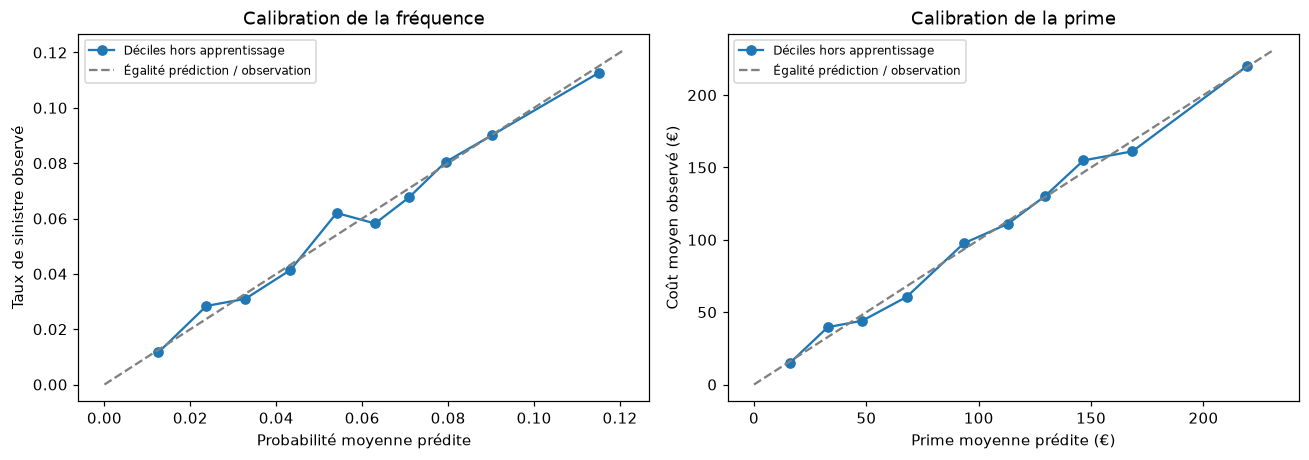

In [13]:
fig,axes=plt.subplots(1,2,figsize=(12,4.3))
for ax,col,target,title,xlabel,ylabel in [
    (axes[0],'proba_pred','claim','Calibration de la fréquence','Probabilité moyenne prédite','Taux de sinistre observé'),
    (axes[1],'pred','observed','Calibration de la prime','Prime moyenne prédite (€)','Coût moyen observé (€)')]:
    z=oof.copy();z['decile']=pd.qcut(z[col],10,labels=False,duplicates='drop')
    cal=z.groupby('decile').agg(prediction=(col,'mean'),observation=(target,'mean'),contrats=('index','size'))
    cal.to_csv(OUT/('calibration_'+col+'.csv'))
    ax.plot(cal.prediction,cal.observation,'o-',label='Déciles hors apprentissage')
    lim=max(cal.prediction.max(),cal.observation.max())*1.05
    ax.plot([0,lim],[0,lim],'--',color='grey',label='Égalité prédiction / observation')
    ax.set(title=title,xlabel=xlabel,ylabel=ylabel);ax.legend(fontsize=8)
figure(fig,'04_calibration.png')

### Erreurs, gros sinistres et segments

La RMSE et la MAE ne privilégient pas les mêmes erreurs. Une baisse de RMSE peut
coexister avec une hausse de MAE. Les coûts extrêmes sont analysés, jamais retirés
de l'apprentissage. Les résultats par contrat affichent leurs effectifs : une
petite différence dans un groupe peu sinistré ne doit pas être surinterprétée.

Les 30 plus gros sinistres (1 % des sinistrés) représentent 23.7% de l’erreur quadratique.


,index,observed,montant_pred,pred,residu
23265,23265,21826.96,1515.572622,93.079840,21733.880160
2408,2408,18246.90,1867.050880,216.591951,18030.308049
27721,27721,16859.40,1966.027683,175.993503,16683.406497
12864,12864,15997.50,1819.594194,180.403106,15817.096894
38429,38429,13813.54,1381.898633,29.443014,13784.096986
24967,24967,12069.04,1605.677418,50.999703,12018.040297
27492,27492,11906.24,1725.572479,107.295525,11798.944475
27763,27763,11724.25,2076.073919,213.412362,11510.837638
25981,25981,11509.30,1882.502506,151.134295,11358.165705
31573,31573,11484.16,1973.004377,248.997334,11235.162666


,variable,modalite,contrats,sinistres,RMSE_principal,RMSE_precedent,MAE_principal,biais_EUR
0,type_contrat,Maxi,32360,2421,626.926819,626.981661,252.812867,-0.408807
1,type_contrat,Median1,4638,139,440.971996,440.964459,86.786490,-0.725342
2,type_contrat,Median2,8759,283,291.071640,291.206752,86.972104,2.018020
3,type_contrat,Mini,4243,74,275.037699,275.090002,49.306939,1.204780
4,utilisation,AllTrips,48,6,450.581802,449.332107,266.956665,-27.076891
5,utilisation,Professional,3667,289,700.322320,700.355212,272.848178,-2.028618
6,utilisation,Retired,13344,803,477.061996,477.098941,184.805081,0.486161
7,utilisation,WorkPrivate,32941,1819,546.506239,546.573455,184.425213,0.256395
8,conducteur2,No,33406,1862,524.963878,525.040276,181.857178,0.054033
9,conducteur2,Yes,16594,1055,574.526679,574.543768,209.679236,0.264528


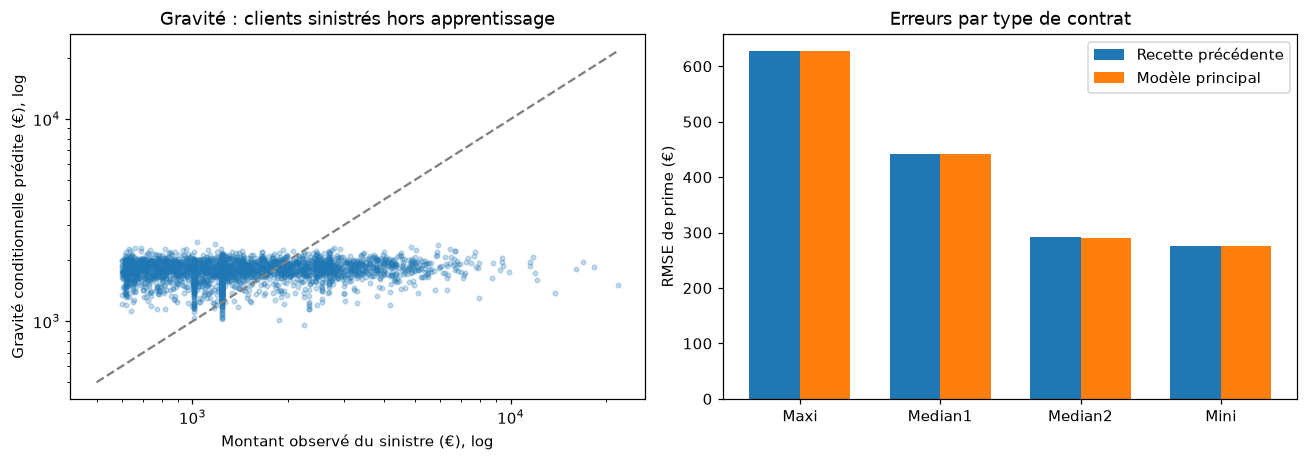

In [14]:
e=oof.copy();e['erreur_carree']=(e.observed-e.pred)**2;e['residu']=e.observed-e.pred
claim_errors=e.loc[e.claim.eq(1)].sort_values('observed',ascending=False)
top_n=int(np.ceil(.01*len(claim_errors)))
tail_share=claim_errors.head(top_n).erreur_carree.sum()/e.erreur_carree.sum()
print(f'Les {top_n} plus gros sinistres (1 % des sinistrés) représentent {tail_share:.1%} de l’erreur quadratique.')
display(claim_errors[['index','observed','montant_pred','pred','residu']].head(12))
segment_rows=[]
for field in ['type_contrat','utilisation','conducteur2']:
    for level,idx in train.groupby(field,dropna=False).groups.items():
        z=oof.loc[idx]
        segment_rows.append({'variable':field,'modalite':str(level),'contrats':len(z),'sinistres':int(z.claim.sum()),
            'RMSE_principal':scores(z.observed,z.pred)['RMSE'],'RMSE_precedent':scores(z.observed,z.incumbent)['RMSE'],
            'MAE_principal':scores(z.observed,z.pred)['MAE'],'biais_EUR':float((z.pred-z.observed).mean())})
segments=pd.DataFrame(segment_rows);segments.to_csv(OUT/'performances_segments.csv',index=False);display(segments)
fig,axes=plt.subplots(1,2,figsize=(12,4.3))
z=e.loc[e.claim.eq(1)]
axes[0].scatter(z.observed,z.montant_pred,s=9,alpha=.25)
lim=max(z.observed.max(),z.montant_pred.max());axes[0].plot([500,lim],[500,lim],'--',color='grey')
axes[0].set(xscale='log',yscale='log',xlabel='Montant observé du sinistre (€), log',ylabel='Gravité conditionnelle prédite (€), log',title='Gravité : clients sinistrés hors apprentissage')
q=segments.loc[segments.variable.eq('type_contrat')];x=np.arange(len(q))
axes[1].bar(x-.18,q.RMSE_precedent,width=.36,label='Recette précédente')
axes[1].bar(x+.18,q.RMSE_principal,width=.36,label='Modèle principal')
axes[1].set_xticks(x,q.modalite);axes[1].set(ylabel='RMSE de prime (€)',title='Erreurs par type de contrat');axes[1].legend()
figure(fig,'05_erreurs_segments.png')

## 8. Importance des groupes de variables sur des clients exclus

Dans chaque pli, nous permutons ensemble les colonnes d'un groupe, trois fois,
sans réapprendre le modèle. La hausse de MSE de prime mesure la sensibilité à cette
perturbation. Une hausse positive indique une information utile dans ce diagnostic.
L'écart-type représente seulement les trois permutations, pas une incertitude
complète d'apprentissage. Une importance faible n'établit pas l'inutilité d'un
champ : les variables peuvent être redondantes. Les permutations peuvent aussi
créer des véhicules ou contrats peu réalistes. La fin de vente sert de contrôle
négatif puisqu'elle n'est utilisée par aucune composante.

,group,mean,std
0,Âge du véhicule,2077.046205,109.576942
1,Contrat et usage,2010.526720,134.189210
2,Caractéristiques techniques et prix,919.966017,45.721469
3,Conducteur principal et bonus,697.239694,157.128725
4,Département,208.029967,3.814463
5,"Marque, modèle, énergie et type",123.818604,119.026718
6,Second conducteur,23.895045,4.623414
7,Fin de vente (contrôle inutilisé),0.000000,0.000000


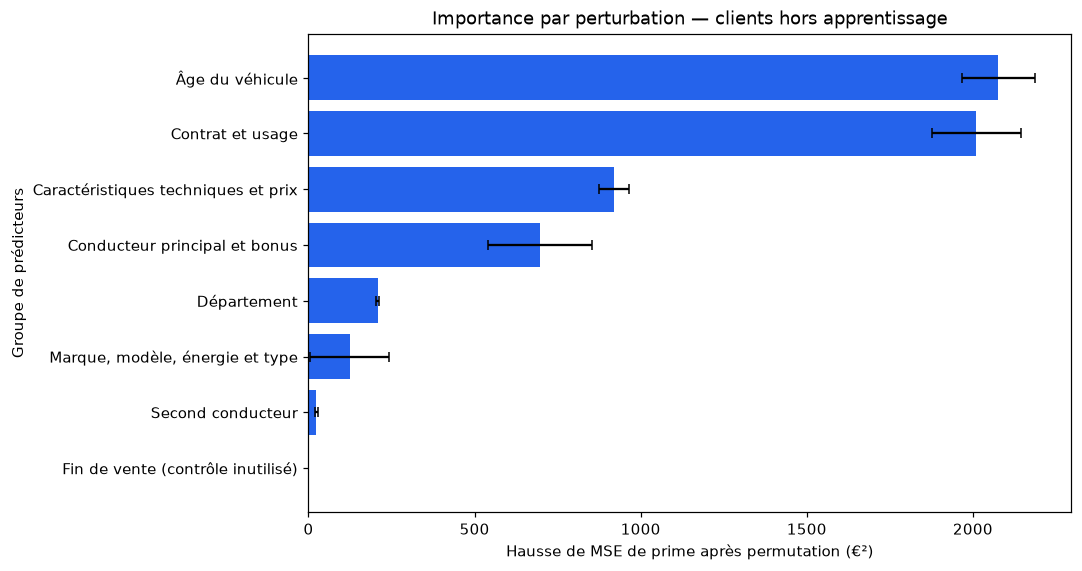

In [15]:
importance=pd.read_csv(OUT/'permutation_importance.csv').sort_values('mean')
display(importance.sort_values('mean',ascending=False))
fig,ax=plt.subplots(figsize=(10,5.3))
ax.barh(importance.group,importance['mean'],xerr=importance['std'].fillna(0),color='#2563eb',capsize=3)
ax.axvline(0,color='grey',lw=1)
ax.set(xlabel='Hausse de MSE de prime après permutation (€²)',ylabel='Groupe de prédicteurs',title='Importance par perturbation — clients hors apprentissage')
figure(fig,'06_importance.png')

### Courbes du modèle pour un profil fixé

Nous faisons varier l'âge du véhicule et le type de contrat pour le profil du
premier prospect, en gardant ses autres valeurs. Ces courbes illustrent le calcul
du modèle ; elles ne sont ni des effets causaux ni la moyenne de tous les assurés.
La plage d'âge reste dans le domaine observé entre les quantiles 1 % et 99 %.

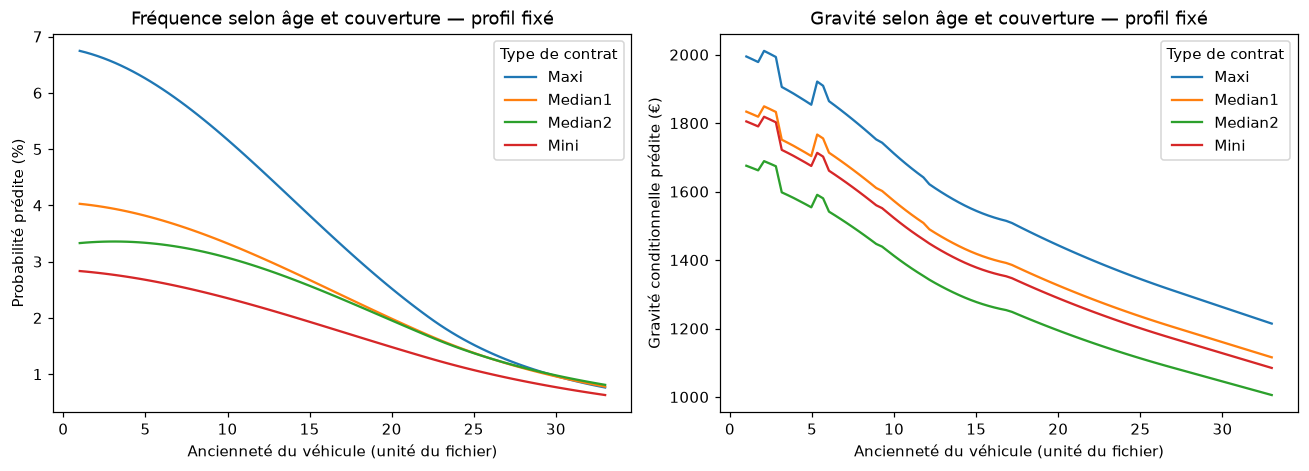

In [16]:
ages=np.linspace(train.anciennete_vehicule.quantile(.01),train.anciennete_vehicule.quantile(.99),90)
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
for contract in sorted(train.type_contrat.unique()):
    profile=pd.concat([test.iloc[[0]]]*len(ages),ignore_index=True)
    profile['anciennete_vehicule']=ages;profile['type_contrat']=contract
    prediction=model.details(profile)
    axes[0].plot(ages,100*prediction.proba_pred,label=contract)
    axes[1].plot(ages,prediction.montant_pred,label=contract)
axes[0].set(xlabel='Ancienneté du véhicule (unité du fichier)',ylabel='Probabilité prédite (%)',title='Fréquence selon âge et couverture — profil fixé')
axes[1].set(xlabel='Ancienneté du véhicule (unité du fichier)',ylabel='Gravité conditionnelle prédite (€)',title='Gravité selon âge et couverture — profil fixé')
for ax in axes:ax.legend(title='Type de contrat')
figure(fig,'07_courbes_profil.png')

## 9. Matrices de confusion : fréquence uniquement

Une matrice de confusion exige un seuil. Le seuil 0,50 peut prédire « sans
sinistre » pour presque tout le monde, avec une exactitude trompeuse dans un jeu
à 5,834 % de positifs. Le second seuil est le taux global d'apprentissage, présenté
uniquement pour comprendre le compromis : il n'est pas sélectionné comme décision
optimale. **Ces seuils ne servent jamais à calculer la soumission.** La gravité est
une régression et n'a pas de matrice de confusion pertinente pour ses euros.

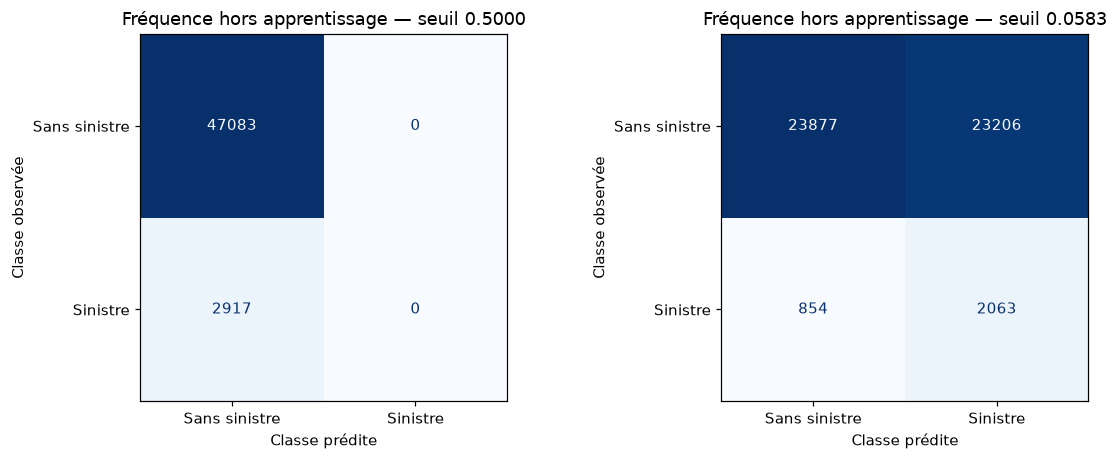

In [17]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,threshold in zip(axes,[.5,float(train.nombre_sinistres.mean())]):
    matrix=confusion_matrix(oof.claim,oof.proba_pred.ge(threshold),labels=[0,1])
    ConfusionMatrixDisplay(matrix,display_labels=['Sans sinistre','Sinistre']).plot(ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set(title=f'Fréquence hors apprentissage — seuil {threshold:.4f}',xlabel='Classe prédite',ylabel='Classe observée')
figure(fig,'08_confusion.png')

## 10. Forces, faiblesses et ce qu'il faudrait améliorer

**Forces :** décomposition fréquence × gravité cohérente ; plis et encodages par
client ; ancre Gamma et corrections régularisées ; coûts extrêmes conservés ;
prédictions positives ; recette et fichier évalué identifiés explicitement.

**Faiblesses :** gain très faible ; peu de sinistres pour de nombreuses catégories ;
forte influence de quelques gros coûts ; modèle composite moins simple à expliquer
qu'un GLM ; MAE plus élevée malgré une baisse de RMSE ; certains segments légèrement
moins bons. Les données et le leaderboard ont déjà été étudiés : l'intervalle
bootstrap descriptif ne couvre pas toute l'incertitude ni les choix humains.

Le Gamma a toujours trois variables, mais **le modèle complet en utilise davantage**.
Le département est présent dans la fréquence et la Ridge. La base historique lit
deux caractères pour le département ; avant un usage sur d'autres zones, notamment
les DOM, cette convention devra être harmonisée avec le traitement métier récent.

**Priorités :** documenter exposition, dates et unités ; réserver une nouvelle
cohorte finale ; disposer de plus de sinistres ; suivre calibration, valeurs
manquantes et erreurs par segment. Le modèle prédit une moyenne, pas une indemnité
garantie ni un intervalle fiable pour chaque assuré.

L'écart entre score public et RMSE locale ne permet pas d'identifier une cause
sans les coûts du test et son échantillonnage. Le score privé n'est pas connu et
la cible historique strictement inférieure à 1365,500 n'est pas atteinte.

## 11. Code d'assemblage et contrôles de livraison

Les objets suivants montrent l'ordre exact des apprentissages et des mélanges.
Le CSV principal doit être celui du dernier modèle, pas un export d'une ancienne
recherche. Le contrôle distingue l'empreinte brute, le contenu normalisé LF et
l'empreinte CRLF du reçu Windows. Les chiffres ne sont pas modifiés pour faire
coïncider artificiellement ces empreintes.

In [18]:
for obj in [f.previous.Premium,f.old.Premium,f.vm.Premium,f.Premium]:
    display(Markdown('**'+obj.__module__+'.'+obj.__name__+'**'));display(Code(inspect.getsource(obj),language='python'))
verification=main.verify_main()
submitted=main.release();display(submitted.head())
summary={'recipe':main.RECIPE,'diagnostic':diagnostic,'tail_top_1pct_claims_SSE_share':float(tail_share),
    'permutation_importance':importance.to_dict(orient='records'),'verification':verification,
    'main_notebook':'modele_principal.ipynb','archives':'archive/'}
main.write_json(OUT/'analyse.json',summary)

{
  "status": "passed",
  "rows": 50000,
  "release_link_verified": true,
  "component_identity_verified": true,
  "forbidden_inputs_invariance": true,
  "unknown_categories_and_missing_values": true,
  "protected_notebook_content_unchanged": true,
  "reproduction": {
    "maximum_absolute_difference_eur": 2.273054633405991e-09,
    "mean_absolute_difference_eur": 1.4409769543699548e-10,
    "numeric_match_rtol_1e_8_atol_1e_6": true
  },
  "model_sha256": "9ba12024b70cd1f08e3389e6a54755d926427a2d451eedffd9eca02f3ad9b796"
}


**refine_severity.Premium**

class Premium:
    def __init__(self,choice):self.choice=choice

    def fit(self,learn):
        self.frequency=r.ReferenceFrequence().fit(learn,learn.nombre_sinistres,learn.id_client)
        claims=learn.loc[learn.nombre_sinistres.eq(1)]
        self.base=GammaMetier({'alpha':.1}).fit(claims,claims.montant_sinistre,claims.id_client)
        if self.choice['candidate']:
            p,s=moments(learn);self.severity=Severity(self.choice['config']).fit(learn,p,s)
        return self

    def details(self,X):
        p=self.frequency.predict_proba(X)[:,1];base=self.base.predict(X);s=base.copy()
        if self.choice['candidate']:
            w=self.choice['weight'];s=(1-w)*base+w*self.severity.predict(X,base)
        return pd.DataFrame(dict(index=X['index'].to_numpy(),proba_pred=p,montant_pred=s,pred=p*s,reference=p*base))

**improve_severity.Premium**

class Premium:
    def __init__(self,choice):self.choice=choice

    def fit(self,learn):
        self.base=previous.Premium(dict(candidate=0,weight=0.,config=None)).fit(learn)
        j=self.choice['candidate'];self.members_=[]
        if j>=0:
            members=[j] if j<len(catalogue()) else stable_members() if j==len(catalogue()) else list(range(len(catalogue())))
            p,s=previous.moments(learn)
            self.members_=[Correction(catalogue()[k]).fit(learn,p,s) for k in members]
        return self

    def details(self,X):
        v=self.base.details(X)
        if self.members_:
            s=v.montant_pred.to_numpy();correction=np.mean([m.predict(X,s) for m in self.members_],axis=0)
            w=self.choice['weight'];v['montant_pred']=(1-w)*s+w*correction
            v['pred']=v.proba_pred.to_numpy()*v.montant_pred.to_numpy()
        return v

**variable_models.Premium**

class Premium:
    def __init__(self,choice):self.choice=choice
    def fit(self,learn):
        self.incumbent=old.Premium(dict(candidate=0,weight=.5)).fit(learn)
        if self.choice['candidate']>=0:
            p,s=previous.moments(learn);self.correction=Correction(catalogue()[self.choice['candidate']]).fit(learn,p,s)
        return self
    def details(self,X):
        v=self.incumbent.details(X);v['incumbent']=v.pred.to_numpy()
        if self.choice['candidate']>=0:
            base=self.incumbent.base.base.predict(X);w=self.choice['weight']
            v['montant_pred']=(1-w)*v.montant_pred+w*self.correction.predict(X,base)
            v['pred']=v.proba_pred*v.montant_pred
        return v

**frequency_curves.Premium**

class Premium:
    def __init__(self,choice):self.choice=choice
    def fit(self,learn):
        self.base=vm.Premium(dict(candidate=12,weight=.25)).fit(learn)
        if self.choice['candidate']>=0:self.correction=Correction(catalogue()[self.choice['candidate']]).fit(learn,auxiliary_probability(learn))
        return self
    def details(self,X):
        v=self.base.details(X);v['incumbent']=v.pred.to_numpy();v['original_probability']=v.proba_pred.to_numpy()
        if self.choice['candidate']>=0:
            v['proba_pred']=expit(logit(v.proba_pred.to_numpy())+self.choice['weight']*self.correction.delta(X))
            v['pred']=v.proba_pred*v.montant_pred
        return v

,index,pred
0,50000,54.144409
1,50001,40.833700
2,50002,215.189921
3,50003,119.202512
4,50004,33.450054


## MODÈLE FINAL RETENU

**Fréquence : logistique C = 0,1 + correction de logit âge/couverture/usage,
alpha = 100, poids = 1.**

**Gravité : 37,5 % Gamma alpha = 0,1 + 37,5 % correction XGBoost (240 arbres,
profondeur 2) + 25 % correction Ridge sur variables étendues, alpha = 10.**

**Soumission : `submission.csv`, 50 000 lignes `index,pred`.
Modèle local : `models/main_model.joblib`.**

Le score public rapporté de 1365,657 reste associé au fichier soumis. La recherche
historique gagne environ 0,05546 € de RMSE locale ; ce progrès marginal n'établit
pas une supériorité universelle ou sur le leaderboard privé.

Pour reproduire : `python run.py train`, `python run.py diagnostic`,
`python run.py verify`, puis `python run.py predict --output reports/main/submission_reproduite.csv`.
Les anciennes recherches sont accessibles dans `archive/` et ne sont plus le modèle actif.

Lecture détaillée : [analyse du modèle](docs/modele_principal.md).
Références : [Gamma](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.GammaRegressor.html),
[Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html),
[splines](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html),
[XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html).